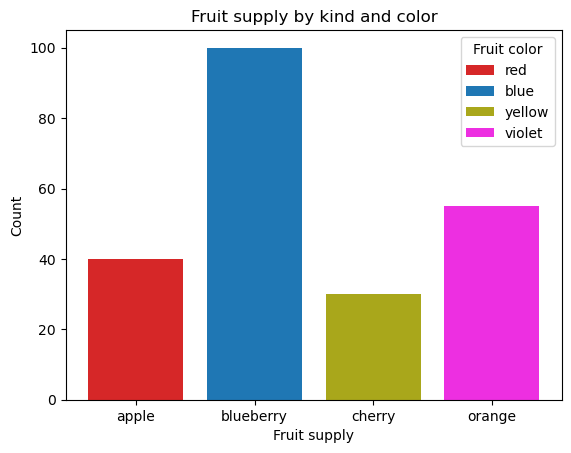

In [2]:
import matplotlib.pyplot as plt

fruits = ['apple', 'blueberry', 'cherry', 'orange']
counts = [40, 100, 30, 55]
bar_labels = ['red', 'blue', 'yellow', 'violet']
bar_colors = ['tab:red', 'tab:blue', '#a9a71b', '#ed2fe1']

plt.bar(fruits, counts, label=bar_labels, color=bar_colors)

plt.xlabel('Fruit supply')
plt.ylabel('Count')
plt.title('Fruit supply by kind and color')
plt.legend(title='Fruit color')

plt.show()

In [5]:
import pandas as pd
path = "data/HR_comma_sep.csv"
df = pd.read_csv(path)
df

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low
...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,support,low
14995,0.37,0.48,2,160,3,0,1,0,support,low
14996,0.37,0.53,2,143,3,0,1,0,support,low
14997,0.11,0.96,6,280,4,0,1,0,support,low


In [8]:
newdf=pd.crosstab(df['Department'],df['salary'])

In [9]:
newdf

salary,high,low,medium
Department,,,
IT,83,609,535
RandD,51,364,372
accounting,74,358,335
hr,45,335,359
management,225,180,225
marketing,80,402,376
product_mng,68,451,383
sales,269,2099,1772
support,141,1146,942


In [12]:
newdf['Total']=newdf['high']+newdf['low']+newdf['medium']

In [13]:
newdf

salary,high,low,medium,Total
Department,,,,
IT,83,609,535,1227
RandD,51,364,372,787
accounting,74,358,335,767
hr,45,335,359,739
management,225,180,225,630
marketing,80,402,376,858
product_mng,68,451,383,902
sales,269,2099,1772,4140
support,141,1146,942,2229


In [14]:
newdf['high_salaryPercentage']=(newdf['high']/newdf['Total'])*100

In [15]:
newdf

salary,high,low,medium,Total,high_salaryPercentage
Department,,,,,
IT,83,609,535,1227,6.764466
RandD,51,364,372,787,6.480305
accounting,74,358,335,767,9.647979
hr,45,335,359,739,6.089310
management,225,180,225,630,35.714286
marketing,80,402,376,858,9.324009
product_mng,68,451,383,902,7.538803
sales,269,2099,1772,4140,6.497585
support,141,1146,942,2229,6.325707


In [18]:
bar_df=newdf.drop(columns=['Total','high_salaryPercentage'])
bar_df

salary,high,low,medium
Department,,,
IT,83,609,535
RandD,51,364,372
accounting,74,358,335
hr,45,335,359
management,225,180,225
marketing,80,402,376
product_mng,68,451,383
sales,269,2099,1772
support,141,1146,942


<Axes: xlabel='Department'>

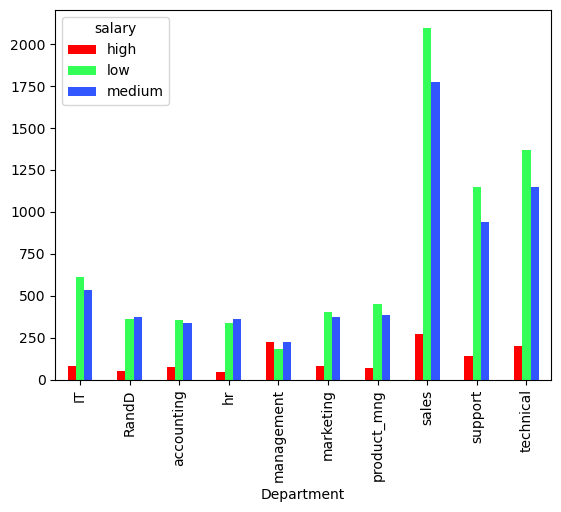

In [27]:
# bar_df.plot.bar(rot=90)
bar_df.plot.bar(rot=90,color=['red', '#33FF57', '#3357FF'])

In [31]:
category = df['Department'].unique()

In [32]:
category

array(['sales', 'accounting', 'hr', 'technical', 'support', 'management',
       'IT', 'product_mng', 'marketing', 'RandD'], dtype=object)

In [40]:
low = bar_df['low'].values
high = bar_df['high'].values
medium = bar_df['medium'].values

In [41]:
high

array([ 83,  51,  74,  45, 225,  80,  68, 269, 141, 201], dtype=int64)

In [42]:
indexes = np.arange(len(high))

In [43]:
indexes

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

([<matplotlib.axis.XTick at 0x22d89551bd0>,
 [Text(0, 0, 'sales'),
  Text(1, 0, 'accounting'),
  Text(2, 0, 'hr'),
  Text(3, 0, 'technical'),
  Text(4, 0, 'support'),
  Text(5, 0, 'management'),
  Text(6, 0, 'IT'),
  Text(7, 0, 'product_mng'),
  Text(8, 0, 'marketing'),
  Text(9, 0, 'RandD')])

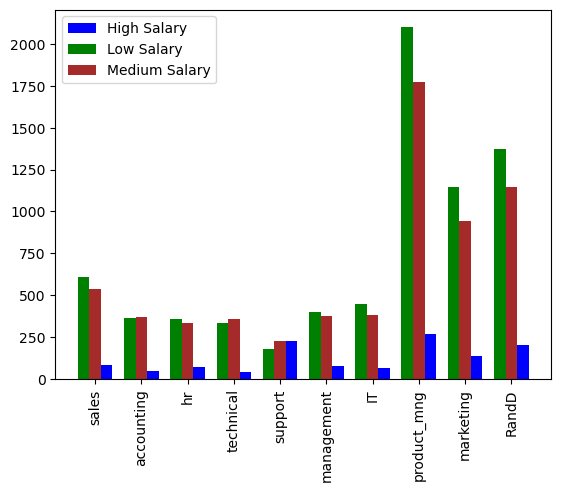

In [59]:
plt.bar(indexes+width,high,width=0.25,label='High Salary',color='blue')
plt.bar(indexes-width,low,width=0.25,label='Low Salary',color='green')
plt.bar(indexes,medium,width=0.25,label='Medium Salary',color='brown')
plt.legend()
plt.xticks(ticks=indexes,labels=category,rotation=90)

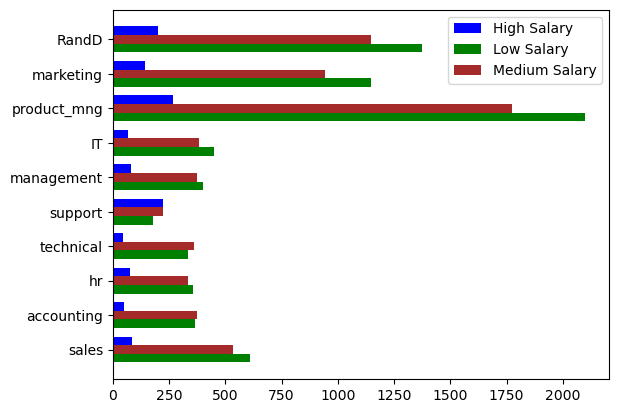

In [62]:
plt.barh(indexes+width, high, height=0.25, label='High Salary', color='blue')
plt.barh(indexes-width, low, height=0.25, label='Low Salary', color='green')
plt.barh(indexes, medium, height=0.25, label='Medium Salary', color='brown')
plt.legend()
plt.yticks(ticks=indexes, labels=category,rotation=0)
plt.show()